# 🧪 LAB: Machine Learning to Predict Concrete Compressive Strength

In this lab, you will apply `PyTorch` to a real-world data problem. You will implement a Neural Network in `PyTorch` using the new functionalities introduced this week and compare its performance with a Support Vector Machine and Linear Regression.

Your goal is to predict the **compressive strength of concrete** (the outcome variable, *Y*) based on a set of input features (*X*), including:
**Cement, Blast Furnace Slag, Fly Ash, Water, Superplasticizer, Coarse Aggregate, Fine Aggregate, and Age.**

This dataset and problem are based on the following paper:

- I-Cheng Yeh, "Modeling of strength of high performance concrete using artificial neural networks," Cement and Concrete Research, Vol. 28, No. 12, pp. 1797-1808 (1998). [Link to the paper](yeh1998.pdf).


---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.

NAME(s) = "Audrey, Claire, Jonathan"

## 0. Overall Instructions 

In this lab, you will work with three models: a **Neural Network**, a **Support Vector Machine (SVM)**, and some form of **Linear Regression**. Each should meet the following requirements:

- **Do not tune the models**. For example, for the Neural Network, choose any number of layers and hidden units you prefer; for the SVM, select a kernel of your choice (e.g., linear, RBF, polynomial), etc.

- **Evaluate model performance using k-fold cross-validation**. That is, run each model using a chosen number of folds (*k*), and report the average performance across all folds. You may select the value of *k* that you want.

- **Be careful with data preprocessing**. Apply all preprocessing steps properly to avoid data leakage (e.g. standardizing features before data splitting)

## 1. Pre-implementation Group Discussion (15 points)

In your group, discuss, agree on, and elaborate the following points:

- **Descriptive analysis**. Identify what exploratory or descriptive analyses you can perform to better understand the relationship between each input variable and the outcome. Consider both visual (e.g., scatter plots, histograms) and statistical summaries.

**answer** We will do three things. First, we will make a table of summary statistics (mean, standard deviation, min, max and quartiles) for every variable, along with the correlation between each input and compressive strength. Second, we will make a histogram of each variable to see its distribution, for example if it is skewed or has a lot of zeros. Third, we will make a scatter plot of each input against compressive strength to see if the relationship looks like a straight line, a curve, or nothing at all.

- **Data preprocessing**. Decide what preprocessing steps are necessary given that you will be using neural networks. 

**answer** All 8 inputs are numbers, so we don't need to encode anything, but we will check for missing values first. The inputs are on very different scales (for example cement goes up to 540 kg but superplasticizer only goes up to about 32 kg), so we need to standardize them, because a neural network trains much better when all the inputs are on a similar scale. To avoid data leakage, the scaler will only be fit on the training folds in each round of cross-validation and then used to transform the test fold, so the test fold never affects the scaling. For the scikit-learn models we can do this by putting the StandardScaler and the model together in a Pipeline, and for the PyTorch network we will fit a new scaler inside every fold. For PyTorch we will also convert the data to float32 tensors and use a DataLoader to split the training data into batches.

- **Model configuration**. Specify which cost function and output layer activation are most appropriate for your problem type (e.g., regression vs. classification). Explain your reasoning based on the nature of the outcome variable.

**answer** This is a regression problem because compressive strength is a continuous number measured in MPa, so we will use mean squared error (MSE) as the cost function (nn.MSELoss in PyTorch). MSE squares each error, so it penalizes big mistakes more than small ones. The output layer will have one unit with no activation function (a linear output), because the prediction has to be able to take any real value. An activation like sigmoid would squash the output between 0 and 1, which would not work for strength values that go up to about 83 MPa. The hidden layers will use ReLU.

- **Performance evaluation**. Describe how you will perform k-fold cross-validation to assess your model’s performance. Include how you will divide the data, compute metrics across folds, and report the final averaged results.

**answer** We will use 5-fold cross-validation with KFold(n_splits=5, shuffle=True, random_state=42). This splits the data into 5 equal parts, and in each round the model is trained on 4 parts (80% of the data) and tested on the part it did not see (20%), so every row is used as test data exactly once. Inside each round we fit the scaler on the training part only, train the model, and then compute the MSE, RMSE and R² on the test part. We won't use accuracy, since that only makes sense for classification. At the end we will report the mean and standard deviation of each metric across the 5 folds. We will use the same folds for the neural network, the scikit-learn MLP, the SVM and linear regression, so the comparison between the models is fair.

USE AS MANY MARKDOWN CELLS AS NEEDED

## 2. Descriptive analysis (10 points)

Apply the descriptive analyses that your group agreed upon in the previous section.

**Load the dataset before beginning the descriptive analysis; you will also use it in the following sections.**

### Loading the data

In [12]:
!pip install -q xlrd

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_excel("Concrete_Data.xls")
df.columns = ["cement", "slag", "fly_ash", "water", "superplasticizer", "coarse_agg", "fine_agg", "age", "strength"]

X = df.drop(columns="strength")
y = df["strength"]

print(df.shape)
df.head()

(1030, 9)


,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


### 1. Summary statistics

All amounts are in kg per m³ of concrete, age is in days and strength is in MPa.

In [14]:
summary = df.describe().T
summary["corr with strength"] = df.corr()["strength"]
summary.round(2)

,count,mean,std,min,25%,50%,75%,max,corr with strength
cement,1030.0,281.17,104.51,102.00,192.38,272.90,350.00,540.0,0.50
slag,1030.0,73.90,86.28,0.00,0.00,22.00,142.95,359.4,0.13
fly_ash,1030.0,54.19,64.00,0.00,0.00,0.00,118.27,200.1,-0.11
water,1030.0,181.57,21.36,121.75,164.90,185.00,192.00,247.0,-0.29
superplasticizer,1030.0,6.20,5.97,0.00,0.00,6.35,10.16,32.2,0.37
coarse_agg,1030.0,972.92,77.75,801.00,932.00,968.00,1029.40,1145.0,-0.16
fine_agg,1030.0,773.58,80.18,594.00,730.95,779.51,824.00,992.6,-0.17
age,1030.0,45.66,63.17,1.00,7.00,28.00,56.00,365.0,0.33
strength,1030.0,35.82,16.71,2.33,23.71,34.44,46.14,82.6,1.00


### 2. Histograms

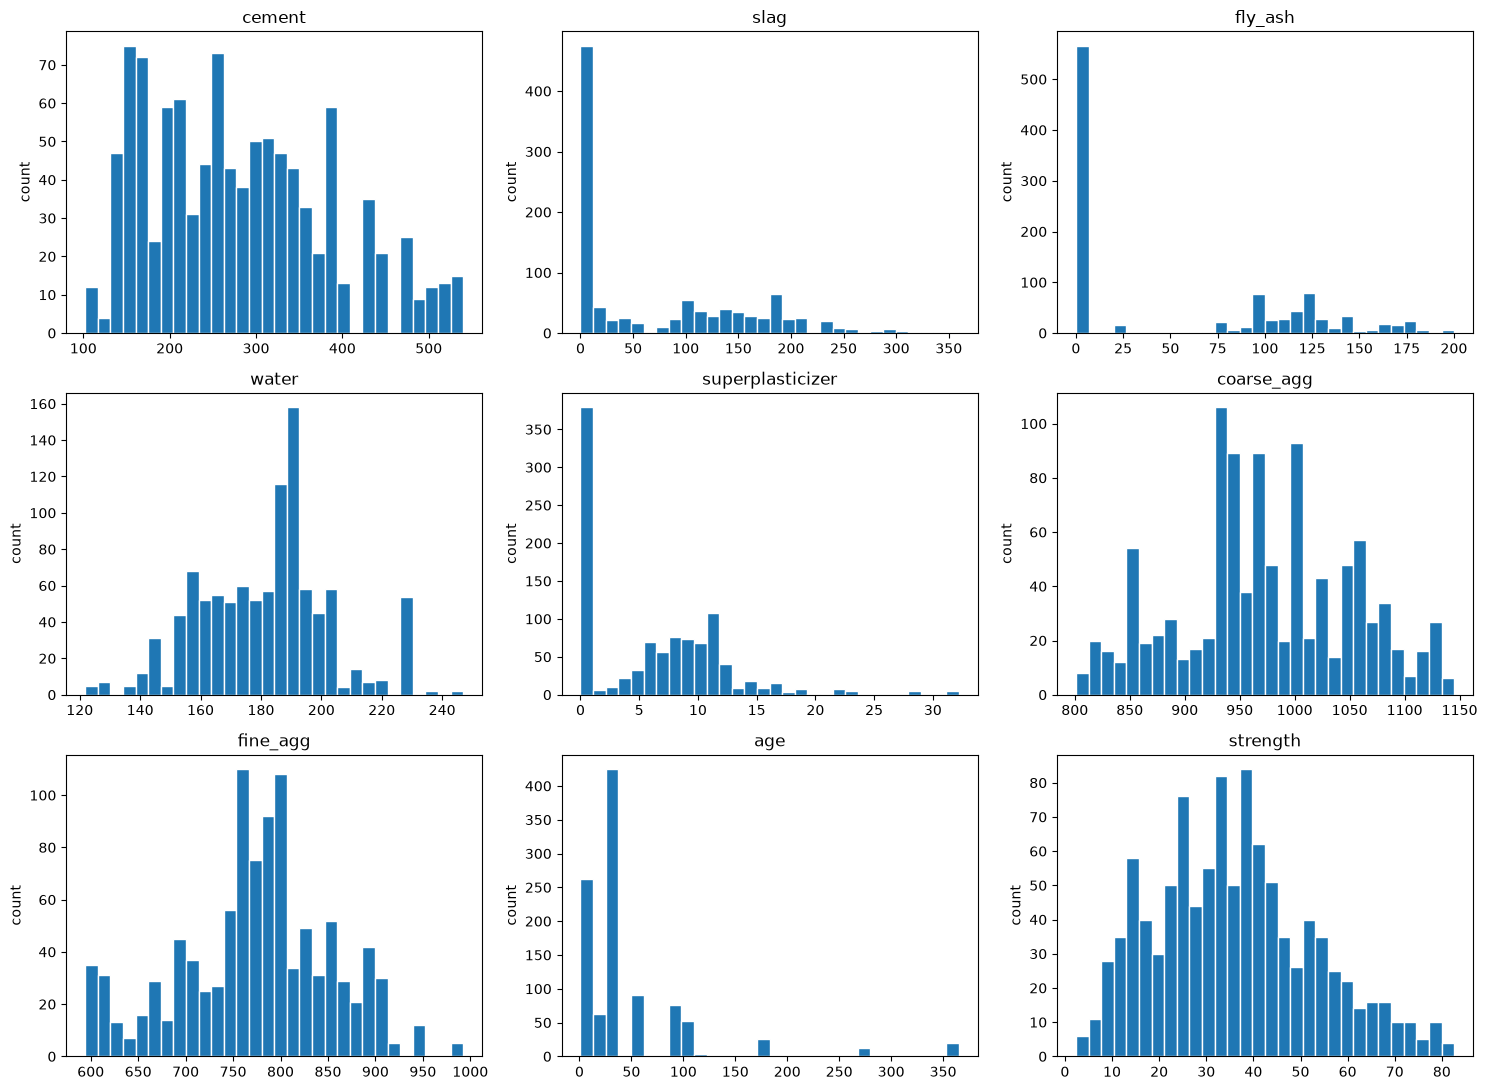

In [4]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.ravel(), df.columns):
    ax.hist(df[col], bins=30, edgecolor="white")
    ax.set_title(col)
    ax.set_ylabel("count")
plt.tight_layout()
plt.show()

### 3. Scatter plots of each input vs. strength

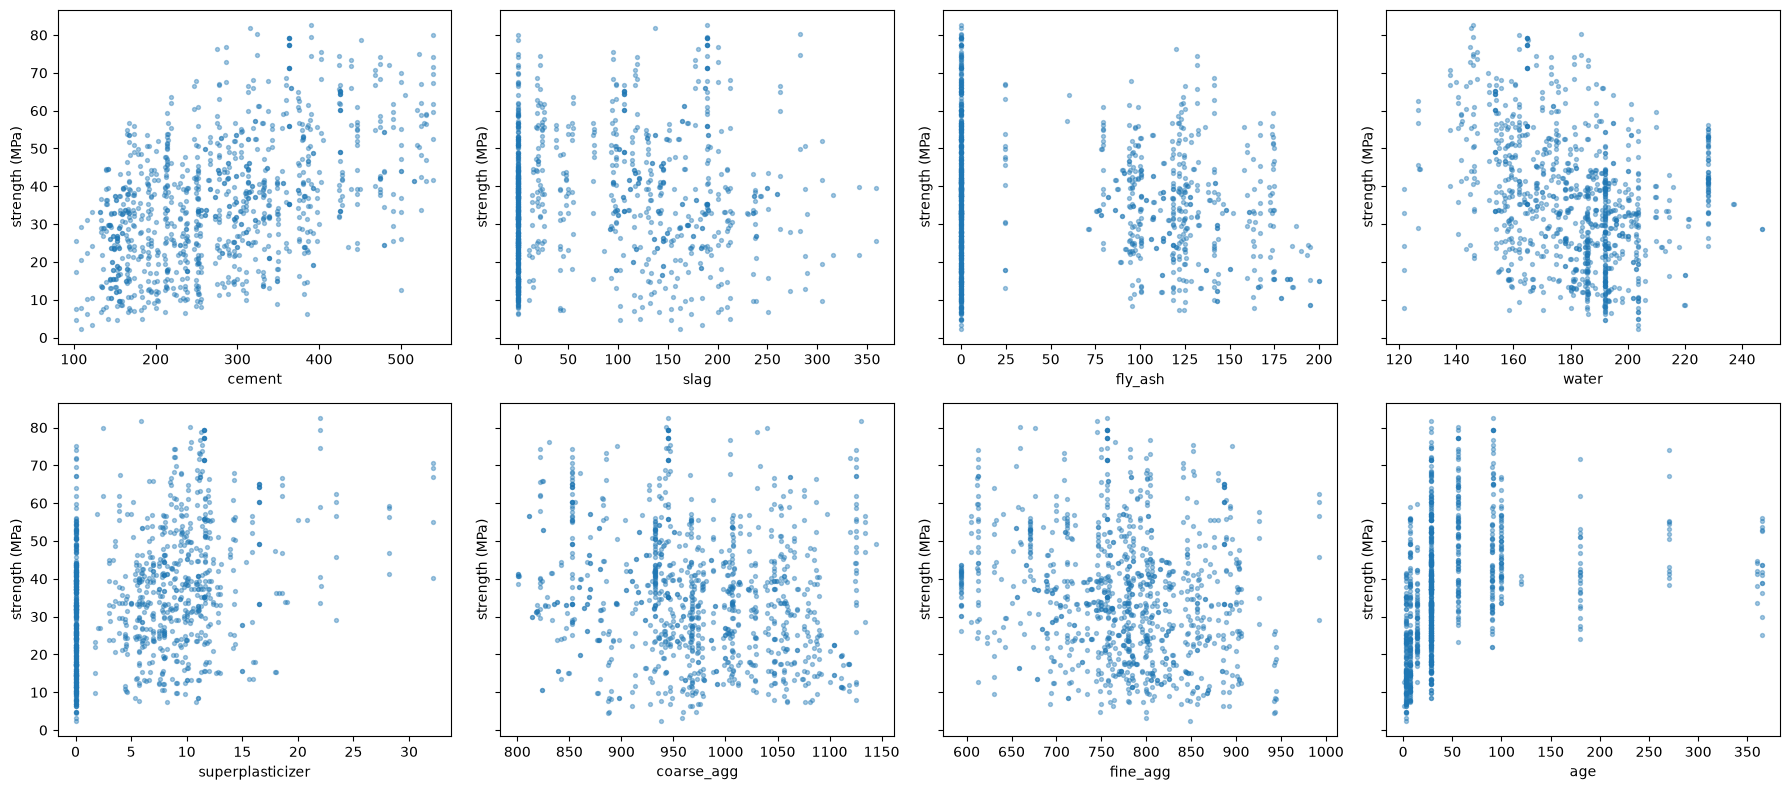

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharey=True)
for ax, col in zip(axes.ravel(), X.columns):
    ax.scatter(df[col], y, s=8, alpha=0.4)
    ax.set_xlabel(col)
    ax.set_ylabel("strength (MPa)")
plt.tight_layout()
plt.show()

### What we found

**Summary statistics.** Every column has 1,030 values, so there is no missing data. The inputs are on very different scales. For example, coarse aggregate goes from 801 to 1,145 kg, but superplasticizer only goes from 0 to 32.2 kg, so we will need to standardize the inputs before training. Strength goes from 2.33 to 82.6 MPa with a mean of 35.82 MPa. Cement has the strongest correlation with strength (0.50), followed by superplasticizer (0.37) and age (0.33), while water has a negative correlation (-0.29). Slag, fly ash, coarse aggregate and fine aggregate are only weakly correlated with strength (between -0.17 and 0.13).

**Histograms.** Slag, fly ash and superplasticizer have a big spike at 0, since a lot of the mixes don't use those ingredients at all. Age is very skewed to the right because most samples were tested at 28 days or earlier and only a few were tested after 100 days. Strength is roughly bell-shaped and a little skewed to the right.

**Scatter plots.** Mixes with more cement usually have higher strength, and mixes with more water tend to be weaker, which matches the correlations. Age does not follow a straight line, since strength goes up a lot in the first month or two and then levels off. For the other inputs the points look mostly like a random cloud. Even for cement the points are very spread out, so no single input can predict strength well on its own. This suggests that strength depends on a combination of the inputs and on curved relationships like age, which a neural network should be able to pick up better than linear regression.

## 3. Neural Network (40 points)

Implement a neural network as you did in the previous lab, but this time leverage the new functionalities introduced this week. Specifically:

- Your class implementing the neural network should inherit from nn.Module.

- Use `nn.Linear` for the linear transformations between layers, `nn.ReLU` for the hidden-layer activations, and the appropriate activation function for the output layer (e.g., `nn.Sigmoid` for binary classification).

- Use the appropriate cost function from `torch.nn` for your task (e.g., `nn.MSELoss`, `nn.BCELoss`).

- Use Adam from `torch.optim` as the optimizer.

- Use `DataLoader` to efficiently do batch processing. You may choose the batch size freely.

Once you have implemented this class, create an instance of it, then train and evaluate your model on the lab dataset.

**Remember to follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.**

### Model setup

We didn't tune the model, we just picked common settings. The network has 2 hidden layers with 64 units each and ReLU, and one output unit with no activation since this is a regression problem. We used `nn.MSELoss` as the cost function, Adam with a learning rate of 0.001 (its default), a batch size of 32 and 300 epochs. To evaluate it we used the same 5-fold cross-validation from Section 1, and in every fold the scaler is fit only on the training part.

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score


class ConcreteNN(nn.Module):
    def __init__(self, n_inputs, n_hidden):
        super().__init__()
        self.hidden1 = nn.Linear(n_inputs, n_hidden)
        self.hidden2 = nn.Linear(n_hidden, n_hidden)
        self.output = nn.Linear(n_hidden, 1)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.hidden1(x))
        x = self.relu(self.hidden2(x))
        return self.output(x)


print(ConcreteNN(n_inputs=8, n_hidden=64))

ConcreteNN(
  (hidden1): Linear(in_features=8, out_features=64, bias=True)
  (hidden2): Linear(in_features=64, out_features=64, bias=True)
  (output): Linear(in_features=64, out_features=1, bias=True)
  (relu): ReLU()
)


In [ ]:
def train_nn(X_train, y_train, epochs=300, lr=0.001, batch_size=32):
    model = ConcreteNN(n_inputs=X_train.shape[1], n_hidden=64)
    loss_fn = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(X_train, y_train), batch_size=batch_size, shuffle=True)

    losses = []
    for epoch in range(epochs):
        epoch_loss = 0
        for X_batch, y_batch in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(X_batch), y_batch)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item() * len(X_batch)
        losses.append(epoch_loss / len(X_train)) 
    return model, losses

### Training and evaluation with 5-fold cross-validation

This takes about a minute to run.

In [ ]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

fold_results = []
fold_losses = []
for fold, (train_idx, test_idx) in enumerate(kf.split(X), start=1):
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X.iloc[train_idx])
    X_test = scaler.transform(X.iloc[test_idx])
    y_train = y.iloc[train_idx].values
    y_test = y.iloc[test_idx].values

    X_train = torch.tensor(X_train, dtype=torch.float32)
    X_test = torch.tensor(X_test, dtype=torch.float32)
    y_train = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)

    torch.manual_seed(42)  
    model, losses = train_nn(X_train, y_train)
    fold_losses.append(losses)

    model.eval()
    with torch.no_grad():
        train_pred = model(X_train).numpy().ravel()
        test_pred = model(X_test).numpy().ravel()

    test_mse = mean_squared_error(y_test, test_pred)
    fold_results.append({
        "fold": fold,
        "train RMSE": mean_squared_error(y_train.numpy().ravel(), train_pred) ** 0.5,
        "test MSE": test_mse,
        "test RMSE": test_mse ** 0.5,
        "test R2": r2_score(y_test, test_pred),
    })

nn_results = pd.DataFrame(fold_results).set_index("fold")
pd.concat([nn_results, nn_results.agg(["mean", "std"])]).round(3)

,train RMSE,test MSE,test RMSE,test R2
1,3.351,31.392,5.603,0.878
2,3.700,31.422,5.606,0.906
3,3.704,29.540,5.435,0.896
4,3.517,25.664,5.066,0.909
5,3.774,24.236,4.923,0.897
mean,3.609,28.451,5.326,0.897
std,0.173,3.324,0.315,0.012


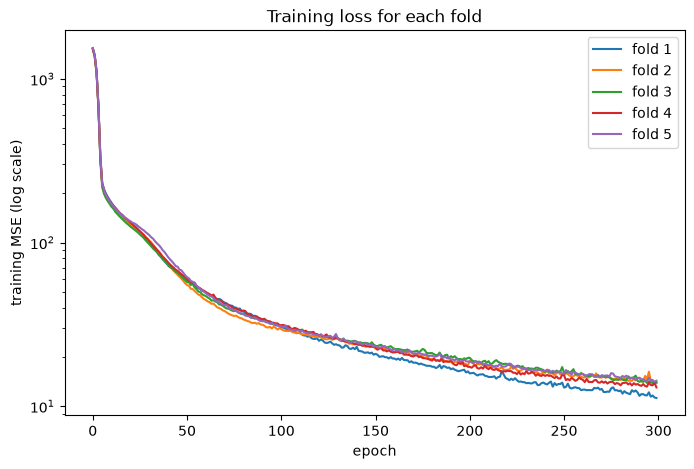

In [9]:
plt.figure(figsize=(8, 5))
for fold, losses in enumerate(fold_losses, start=1):
    plt.plot(losses, label=f"fold {fold}")
plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("training MSE (log scale)")
plt.title("Training loss for each fold")
plt.legend()
plt.show()

### Results

Across the 5 folds, the neural network had an average test RMSE of 5.36 MPa (standard deviation 0.36) and an average test R² of 0.896. This means a typical prediction on concrete the model hasn't seen is off by about 5.4 MPa, and the model explains about 90% of the variation in strength. That is a lot better than just guessing the average strength every time, which would give an RMSE of about 16.7 MPa (the standard deviation of strength from Section 2). The results were also pretty consistent across the folds, with the test RMSE only going from 4.92 to 5.78 MPa, so the model doesn't depend much on which rows end up in the test fold.

The training RMSE (3.61 MPa on average) is lower than the test RMSE (5.36 MPa), so the model fits the data it was trained on better than new data, which means there is some overfitting. The training loss curves drop really fast in the first few epochs, go from about 200 to about 30 by epoch 100, and then keep going down slowly until epoch 300. All 5 folds look almost the same, so the training was stable no matter which part of the data was used.

## 4. Replication (10 points)

Replicate your neural network experiment using the corresponding model class from `scikit-learn`: https://scikit-learn.org/stable/api/sklearn.neural_network.html. Be sure to apply the same neural network architecture as well as the same procedures for model evaluation and preprocessing to ensure a fair comparison.

**Remember**: Follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.

In [10]:
# USE AS MANY CELLS AS NEEDED

## 5. Comparison (20 points)

Apply a Support Vector Machine (SVM) and Linear Regression model to the dataset, and compare their performance with that of your Neural Network.

Discuss any similarities or differences you observe in their results and provide possible explanations for these patterns.

Be sure to apply the k-fold cross-validation procedure to ensure a fair comparison across all models.

**Remember**: Follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.

In [11]:
# USE AS MANY CELLS AS NEEDED

## 6. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE